In [147]:
import importlib
import math
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)

ROOT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").exists()),
    None
)

if ROOT_DIR is None:
    raise FileNotFoundError("Não encontrei a pasta 'utils'.")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

candidates = [
    ROOT_DIR / "data" / "processed",
    Path.cwd() / "data" / "processed",
    Path.cwd().parent / "data" / "processed",
    Path.cwd().parent.parent / "data" / "processed",
]

DATA_DIR = next((p for p in candidates if (p / "X_train.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Não encontrei data/processed/X_train.csv. Ajuste DATA_DIR manualmente.")

sns.set_theme(style="whitegrid", context="notebook")

from utils.build_scaler import build_scaler
from utils.donut_chart import donut_chart

import utils.kmeans_smote_utils as km_utils
importlib.reload(km_utils)
from utils.kmeans_smote_utils import fit_smote_mrs_scenarios, smote_mrs

In [148]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv")
y_test = pd.read_csv(DATA_DIR / "y_test.csv")

if list(X_train.columns) != list(X_test.columns):
    raise ValueError(
        "X_train e X_test precisam ter as mesmas colunas, na mesma ordem."
    )

if list(y_train.columns) != list(y_test.columns):
    raise ValueError(
        "y_train e y_test precisam ter as mesmas colunas, na mesma ordem."
    )

important_variables = [
    "FOLATE",
    "TSD",
    "HGB",
    "B12",
    "GENDER",
    "FERRITTE",
    "HCT",
    "RBC",
    "SD",
    "MCH"
]

X_train = X_train[important_variables].copy()
X_test  = X_test[important_variables].copy()

print(f"X Treino: {X_train.shape}")
print(f"X Teste:  {X_test.shape}")
display(X_train.head())

print(f"Y Treino: {y_train.shape}")
print(f"Y Teste:  {y_test.shape}")
display(y_train.head())

X Treino: (10648, 10)
X Teste:  (4564, 10)


,FOLATE,TSD,HGB,B12,GENDER,FERRITTE,HCT,RBC,SD,MCH
0,10.63,6.566347,11.56,212.1,0,8.09,38.33,4.95,28.80,23.35
1,11.69,28.025696,14.81,420.8,0,47.39,41.26,4.82,89.87,30.72
2,20.00,14.156627,13.90,312.4,0,34.34,41.30,4.65,47.00,29.90
3,7.02,29.090301,14.70,149.1,1,55.01,43.60,4.88,95.71,30.10
4,8.99,23.604053,12.20,755.9,0,206.40,34.20,4.18,71.99,29.20


Y Treino: (10648, 1)
Y Teste:  (4564, 1)


,All_Class
0,2
1,0
2,0
3,0
4,0


In [149]:
N_CLUSTERS = 5
RANDOM_STATE = 2005

NOMES_CLASSES = {
    0: "Sem anemia",
    1: "HGB-anemia",
    2: "Deficiência de ferro",
    3: "Deficiência de folato",
    4: "Deficiência de B12",
}

model = KMeans(
    n_clusters=N_CLUSTERS,
    n_init=10,
    random_state=RANDOM_STATE
)

scalers_base = build_scaler(model)
results_base = {}

for name, pipeline in scalers_base.items():
    pipeline.fit(X_train)
    results_base[name] = pipeline.predict(X_test)

In [150]:
R = 5
RATIO = 0.3

y_tr = y_train.squeeze()

scalers = build_scaler(KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE))
results = {}
mrs_data = {}

for name, pipeline in scalers.items():
    scaler = pipeline.named_steps["scaler"]
    pipeline.steps[-1] = ("model", clone(pipeline.named_steps["model"]))

    Xs_train = scaler.fit_transform(X_train)

    X_mrs, y_mrs, resumo = smote_mrs(
        Xs_train, y_tr, n_groups=R, target_ratio=RATIO, random_state=RANDOM_STATE
    )

    pipeline.named_steps["model"].fit(X_mrs)
    results[name] = pipeline.predict(X_test)
    mrs_data[name] = {"X": X_mrs, "y": y_mrs, "resumo": resumo}

    sint = resumo["Sintéticos (SMOTE)"].sum() + resumo["Duplicados (ROS)"].sum()
    print(f"[{name:9s}] treino {len(X_train)} -> {len(X_mrs)} linhas "
          f"({sint / len(X_mrs):.1%} artificiais) | { {int(k): v for k, v in sorted(Counter(y_mrs).items())} }")

[standard ] treino 10648 -> 18329 linhas (41.9% artificiais) | {0: 7060, 1: 2733, 2: 4216, 3: 2160, 4: 2160}
[minmax   ] treino 10648 -> 17402 linhas (38.8% artificiais) | {0: 6770, 1: 2522, 2: 4254, 3: 1928, 4: 1928}
[robust   ] treino 10648 -> 18821 linhas (43.4% artificiais) | {0: 7094, 1: 2675, 2: 4112, 3: 2470, 4: 2470}
[quantile ] treino 10648 -> 17133 linhas (37.9% artificiais) | {0: 6772, 1: 2535, 2: 4307, 3: 1115, 4: 2404}


In [151]:
originais = y_tr.value_counts().sort_index()

participacao = pd.DataFrame({
    nome: 1 - originais / pd.Series(d["y"]).value_counts().sort_index()
    for nome, d in mrs_data.items()
})
participacao.index = participacao.index.map(NOMES_CLASSES)

display(
    (participacao * 100)
    .rename_axis(index="Classe", columns="Escalonador")
    .style.format("{:.1f}%")
)

Escalonador,standard,minmax,robust,quantile
Classe,,,,
Sem anemia,4.1%,0.0%,4.6%,0.0%
HGB-anemia,74.0%,71.8%,73.4%,72.0%
Deficiência de ferro,30.7%,31.3%,28.9%,32.2%
Deficiência de folato,95.1%,94.5%,95.7%,90.5%
Deficiência de B12,93.6%,92.8%,94.4%,94.2%


In [152]:
def metricas(scalers_d, results_d, cenario):
    linhas = []
    for name, pipe in scalers_d.items():
        cl = results_d[name]
        Xt = pipe[:-1].transform(X_test)
        linhas.append({
            "Cenário": cenario, "Scaler": name,
            "ARI": adjusted_rand_score(y_test.squeeze(), cl),
            "NMI": normalized_mutual_info_score(y_test.squeeze(), cl),
            "Silhouette": silhouette_score(Xt, cl),
            "Davies-Bouldin": davies_bouldin_score(Xt, cl),
        })
    return pd.DataFrame(linhas)

comparacao = pd.concat([metricas(scalers_base, results_base, "Sem SMOTE"),
                        metricas(scalers, results, "SMOTE-MRS")])
display(comparacao.sort_values(["Scaler", "Cenário"]).reset_index(drop=True)
        .style.format({"ARI": "{:.4f}", "NMI": "{:.4f}", "Silhouette": "{:.4f}", "Davies-Bouldin": "{:.4f}"}))

,Cenário,Scaler,ARI,NMI,Silhouette,Davies-Bouldin
0,SMOTE-MRS,minmax,0.1549,0.1722,0.1848,1.8505
1,Sem SMOTE,minmax,0.2047,0.2130,0.2568,1.5423
2,SMOTE-MRS,quantile,0.1727,0.2031,0.1658,1.8656
3,Sem SMOTE,quantile,0.1811,0.2705,0.2116,1.6268
4,SMOTE-MRS,robust,0.2719,0.2833,0.1555,1.6590
5,Sem SMOTE,robust,0.1772,0.2794,0.1375,1.7566
6,SMOTE-MRS,standard,0.2226,0.2114,0.1695,1.6657
7,Sem SMOTE,standard,0.1972,0.2946,0.1556,1.6828


In [153]:
for name, d in mrs_data.items():
    print(f"\n== {name} ==")
    display(d["resumo"])


== standard ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS),Total final
0,0,2192,2393,0,4585
1,1,2747,948,485,4180
2,2,1008,584,0,1592
3,3,1448,222,0,1670
4,4,3253,3049,0,6302



== minmax ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS),Total final
0,0,2085,2009,0,4094
1,1,3783,3690,0,7473
2,2,2407,0,449,2856
3,3,1049,178,0,1227
4,4,1324,428,0,1752



== robust ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS),Total final
0,0,2607,1352,0,3959
1,1,3360,2580,0,5940
2,2,1032,587,604,2223
3,3,1306,272,0,1578
4,4,2343,2081,697,5121



== quantile ==


,Grupo,Originais,Sintéticos (SMOTE),Duplicados (ROS),Total final
0,0,1367,332,0,1699
1,1,2720,2374,0,5094
2,2,2041,2325,0,4366
3,3,2510,965,0,3475
4,4,2010,489,0,2499


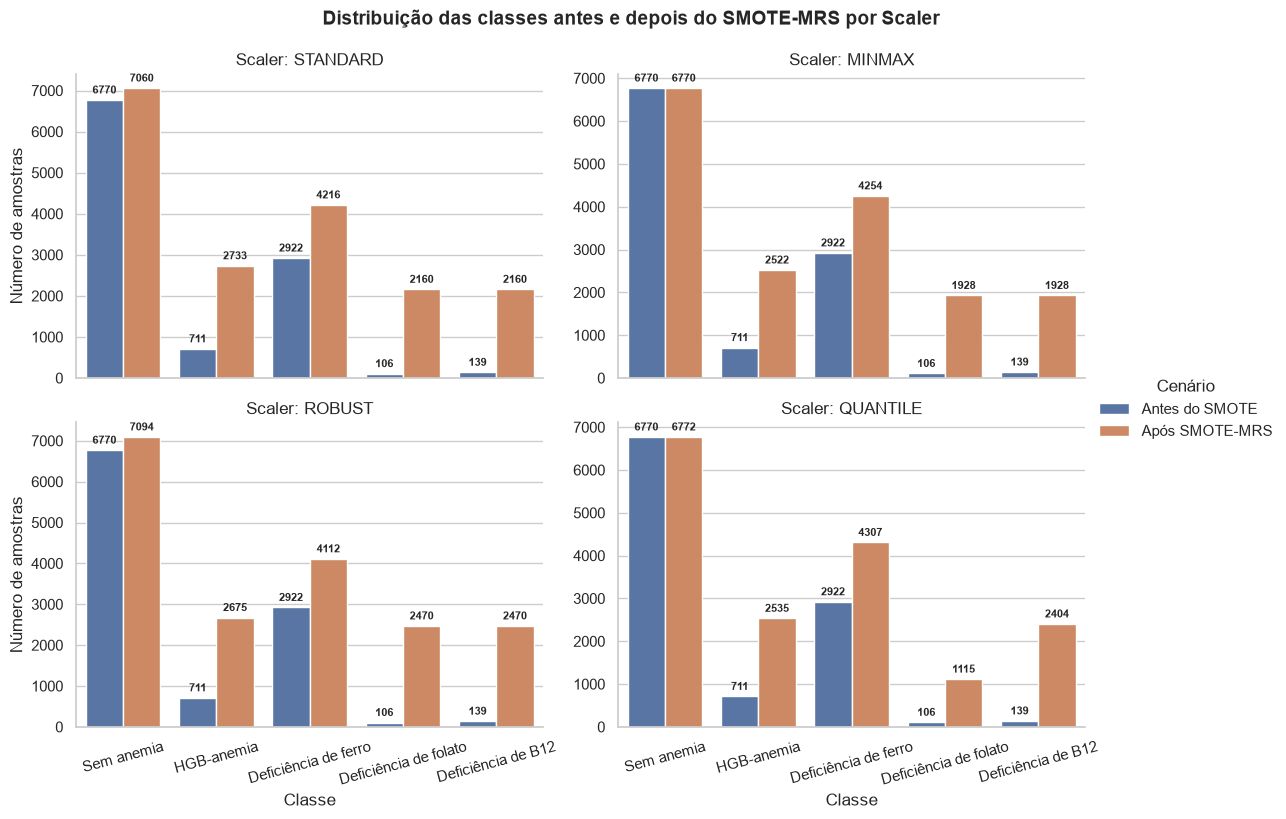

In [154]:
nomes_classes = {
    0: "Sem anemia",
    1: "HGB-anemia",
    2: "Deficiência de ferro",
    3: "Deficiência de folato",
    4: "Deficiência de B12",
}

orig_counts = pd.Series(y_tr).value_counts().sort_index()

frames = []
for nome_scaler, d in mrs_data.items():
    smote_counts = pd.Series(d["y"]).value_counts().sort_index()
    
    contagem_original = pd.DataFrame({
        "Classe": orig_counts.index.map(nomes_classes),
        "Quantidade": orig_counts.values,
        "Cenário": "Antes do SMOTE",
        "Scaler": nome_scaler.upper()
    })
    
    contagem_smote = pd.DataFrame({
        "Classe": smote_counts.index.map(nomes_classes),
        "Quantidade": smote_counts.values,
        "Cenário": "Após SMOTE-MRS",
        "Scaler": nome_scaler.upper()
    })
    
    frames.extend([contagem_original, contagem_smote])

distribuicao = pd.concat(frames, ignore_index=True)

g = sns.catplot(
    data=distribuicao,
    x="Classe",
    y="Quantidade",
    hue="Cenário",
    col="Scaler",
    col_wrap=2,
    kind="bar",
    height=4,
    aspect=1.4,
    palette=["#4C72B0", "#DD8452"],
    sharey=False
)

g.set_axis_labels("Classe", "Número de amostras")
g.set_titles("Scaler: {col_name}")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("Distribuição das classes antes e depois do SMOTE-MRS por Scaler", fontsize=14, fontweight="bold")

for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=3, fontsize=8, fontweight="bold")
    plt.setp(ax.get_xticklabels(), rotation=15)

plt.show()

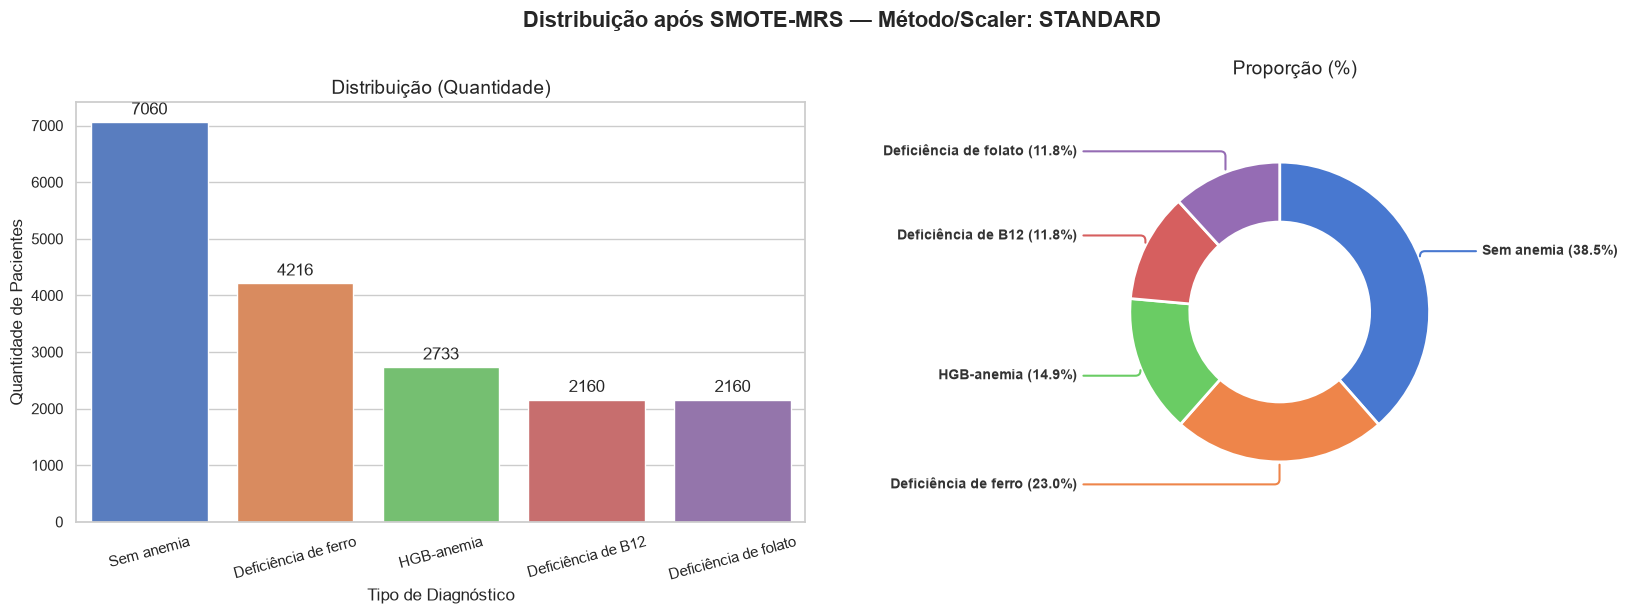

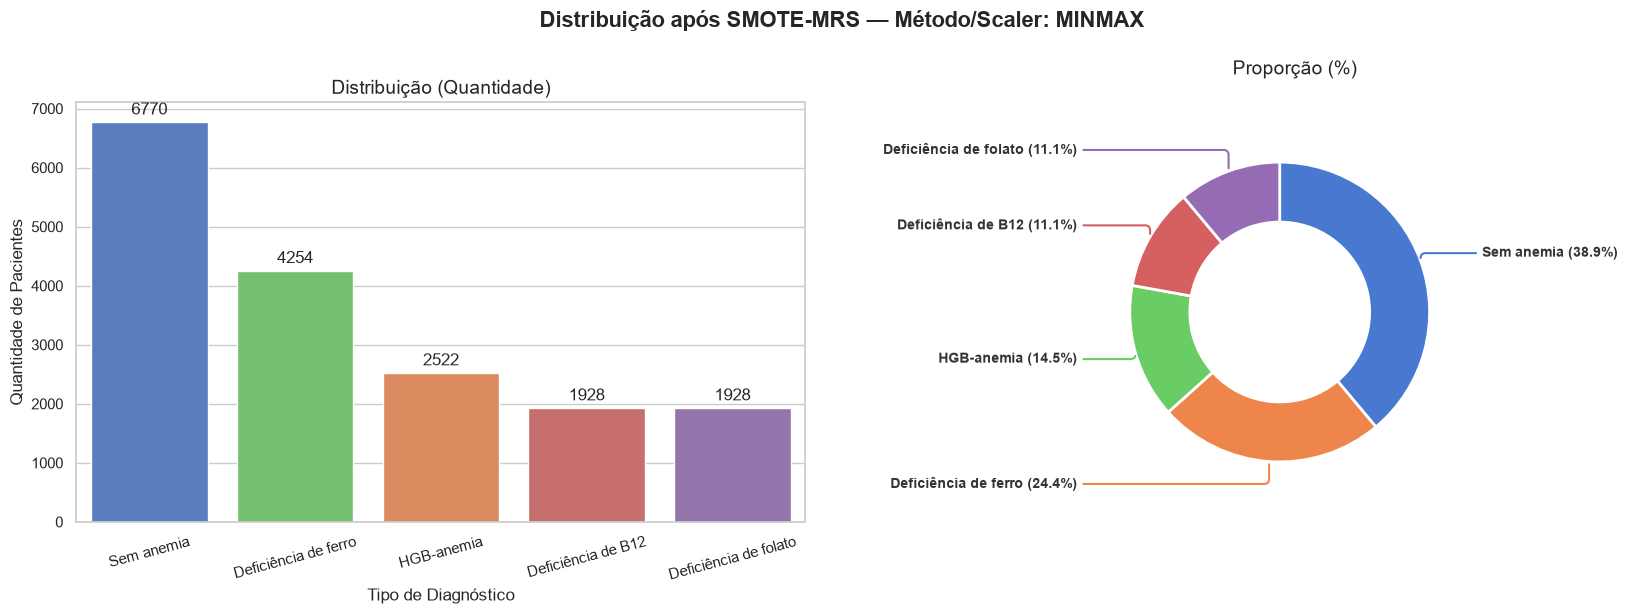

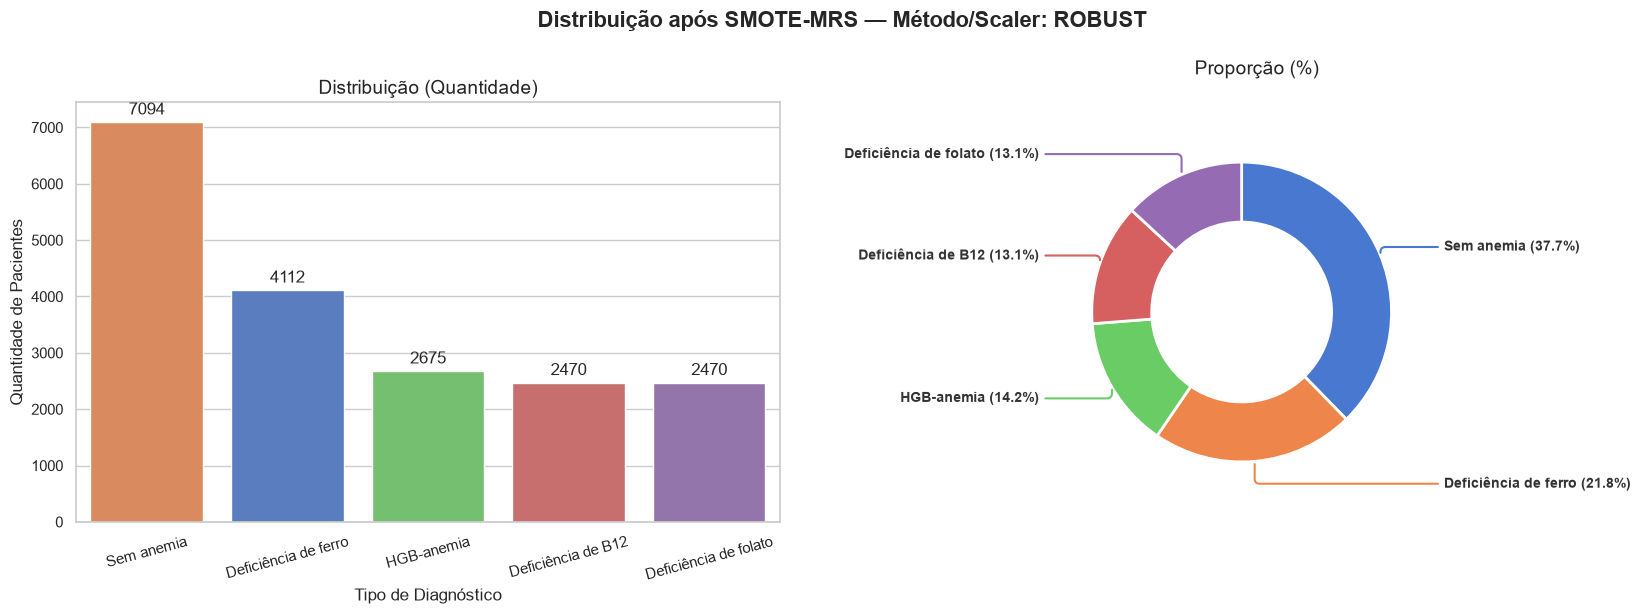

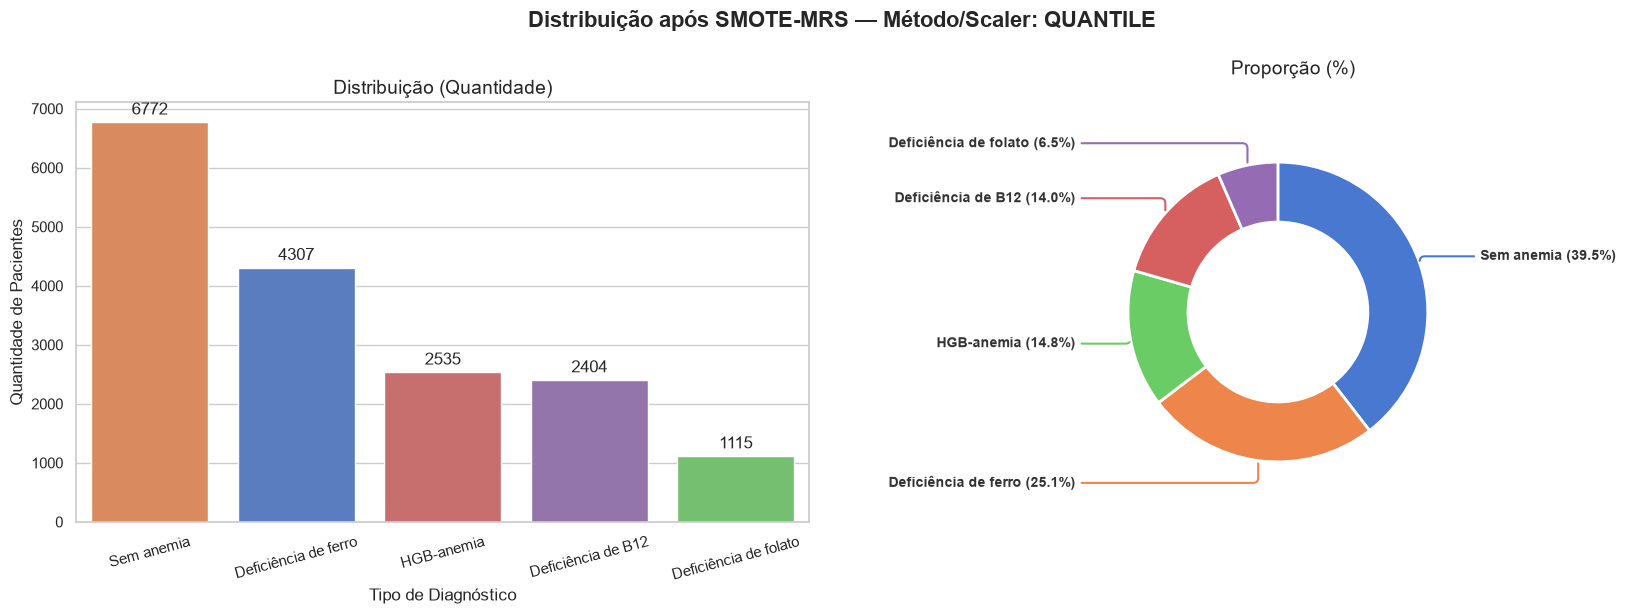

In [155]:
for nome_scaler, item in mrs_data.items():
  df_metodo = pd.DataFrame({"All_Class": item["y"]})

  donut_chart(
      df=df_metodo,
      coluna="All_Class",
      mapa_nomes=nomes_classes,
      titulo_geral=(
          f"Distribuição após SMOTE-MRS — Método/Scaler: {nome_scaler.upper()}"
      ),
      xlabel="Tipo de Diagnóstico",
      ylabel="Quantidade de Pacientes",
      paleta="muted",
  )

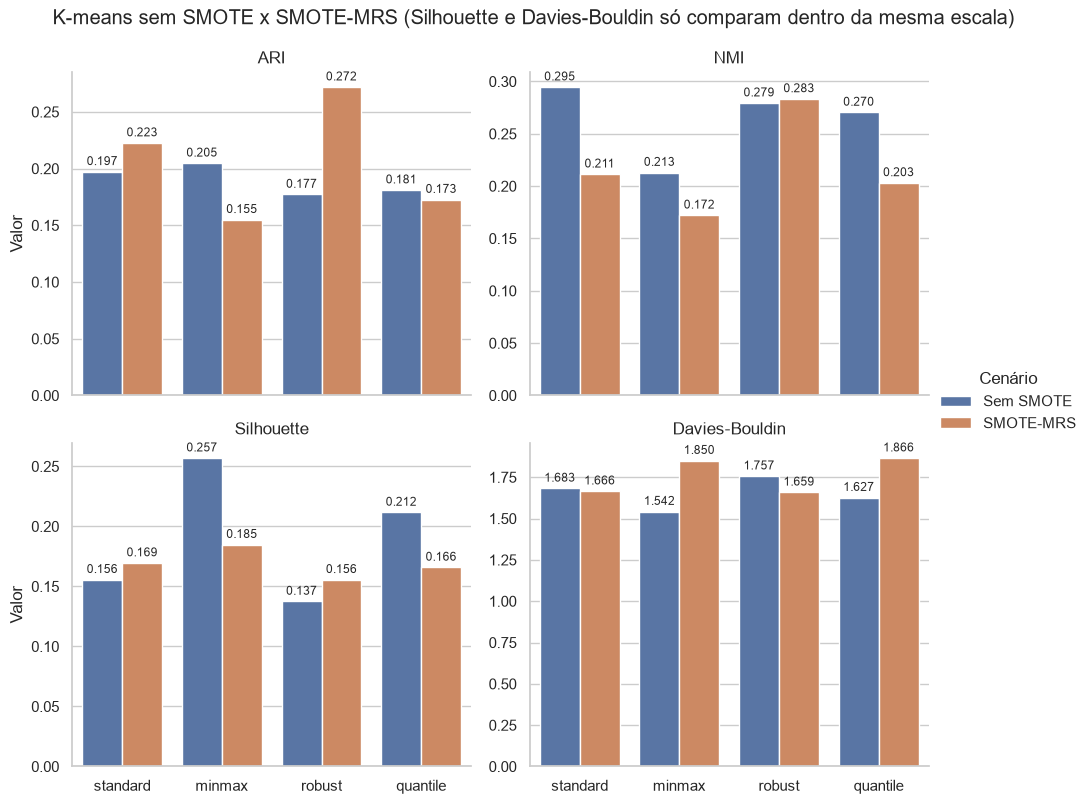

In [156]:
metricas_plot = comparacao.melt(
    id_vars=["Cenário", "Scaler"],
    value_vars=["ARI", "NMI", "Silhouette", "Davies-Bouldin"],
    var_name="Métrica",
    value_name="Valor"
)

g = sns.catplot(
    data=metricas_plot,
    x="Scaler",
    y="Valor",
    hue="Cenário",
    col="Métrica",
    kind="bar",
    col_wrap=2,
    height=4,
    aspect=1.2,
    sharey=False
)

g.set_titles("{col_name}")
g.set_axis_labels("", "Valor")
g.fig.suptitle(
    "K-means sem SMOTE x SMOTE-MRS (Silhouette e Davies-Bouldin só comparam dentro da mesma escala)",
    y=1.03,
)

for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(
            container, 
            fmt="%.3f",
            padding=3,
            fontsize=85 / 10,
            rotation=0
        )

plt.show()

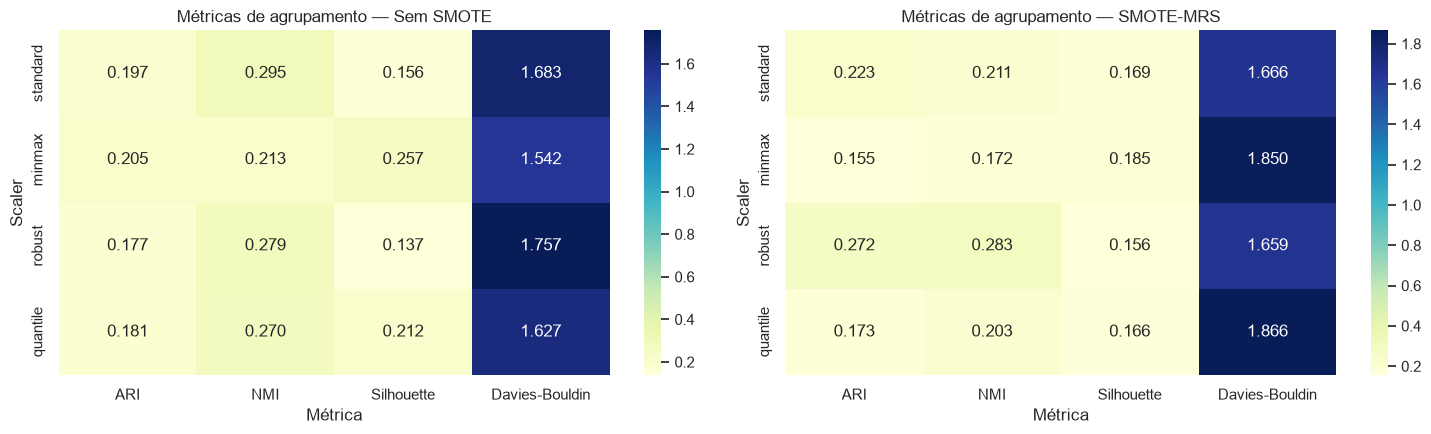

In [157]:
cenarios = comparacao["Cenário"].unique()
n_cenarios = len(cenarios)
ncols = 2
nrows = math.ceil(n_cenarios / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes_flat = np.atleast_1d(axes).ravel()

for ax, cenario in zip(axes_flat, cenarios):
    tabela = (
        comparacao[comparacao["Cenário"] == cenario]
        .set_index("Scaler")[["ARI", "NMI", "Silhouette", "Davies-Bouldin"]]
    )

    sns.heatmap(
        tabela,
        annot=True,
        fmt=".3f",
        cmap="YlGnBu",
        ax=ax,
    )

    ax.set_title(f"Métricas de agrupamento — {cenario}")
    ax.set_xlabel("Métrica")
    ax.set_ylabel("Scaler")

for ax in axes_flat[n_cenarios:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

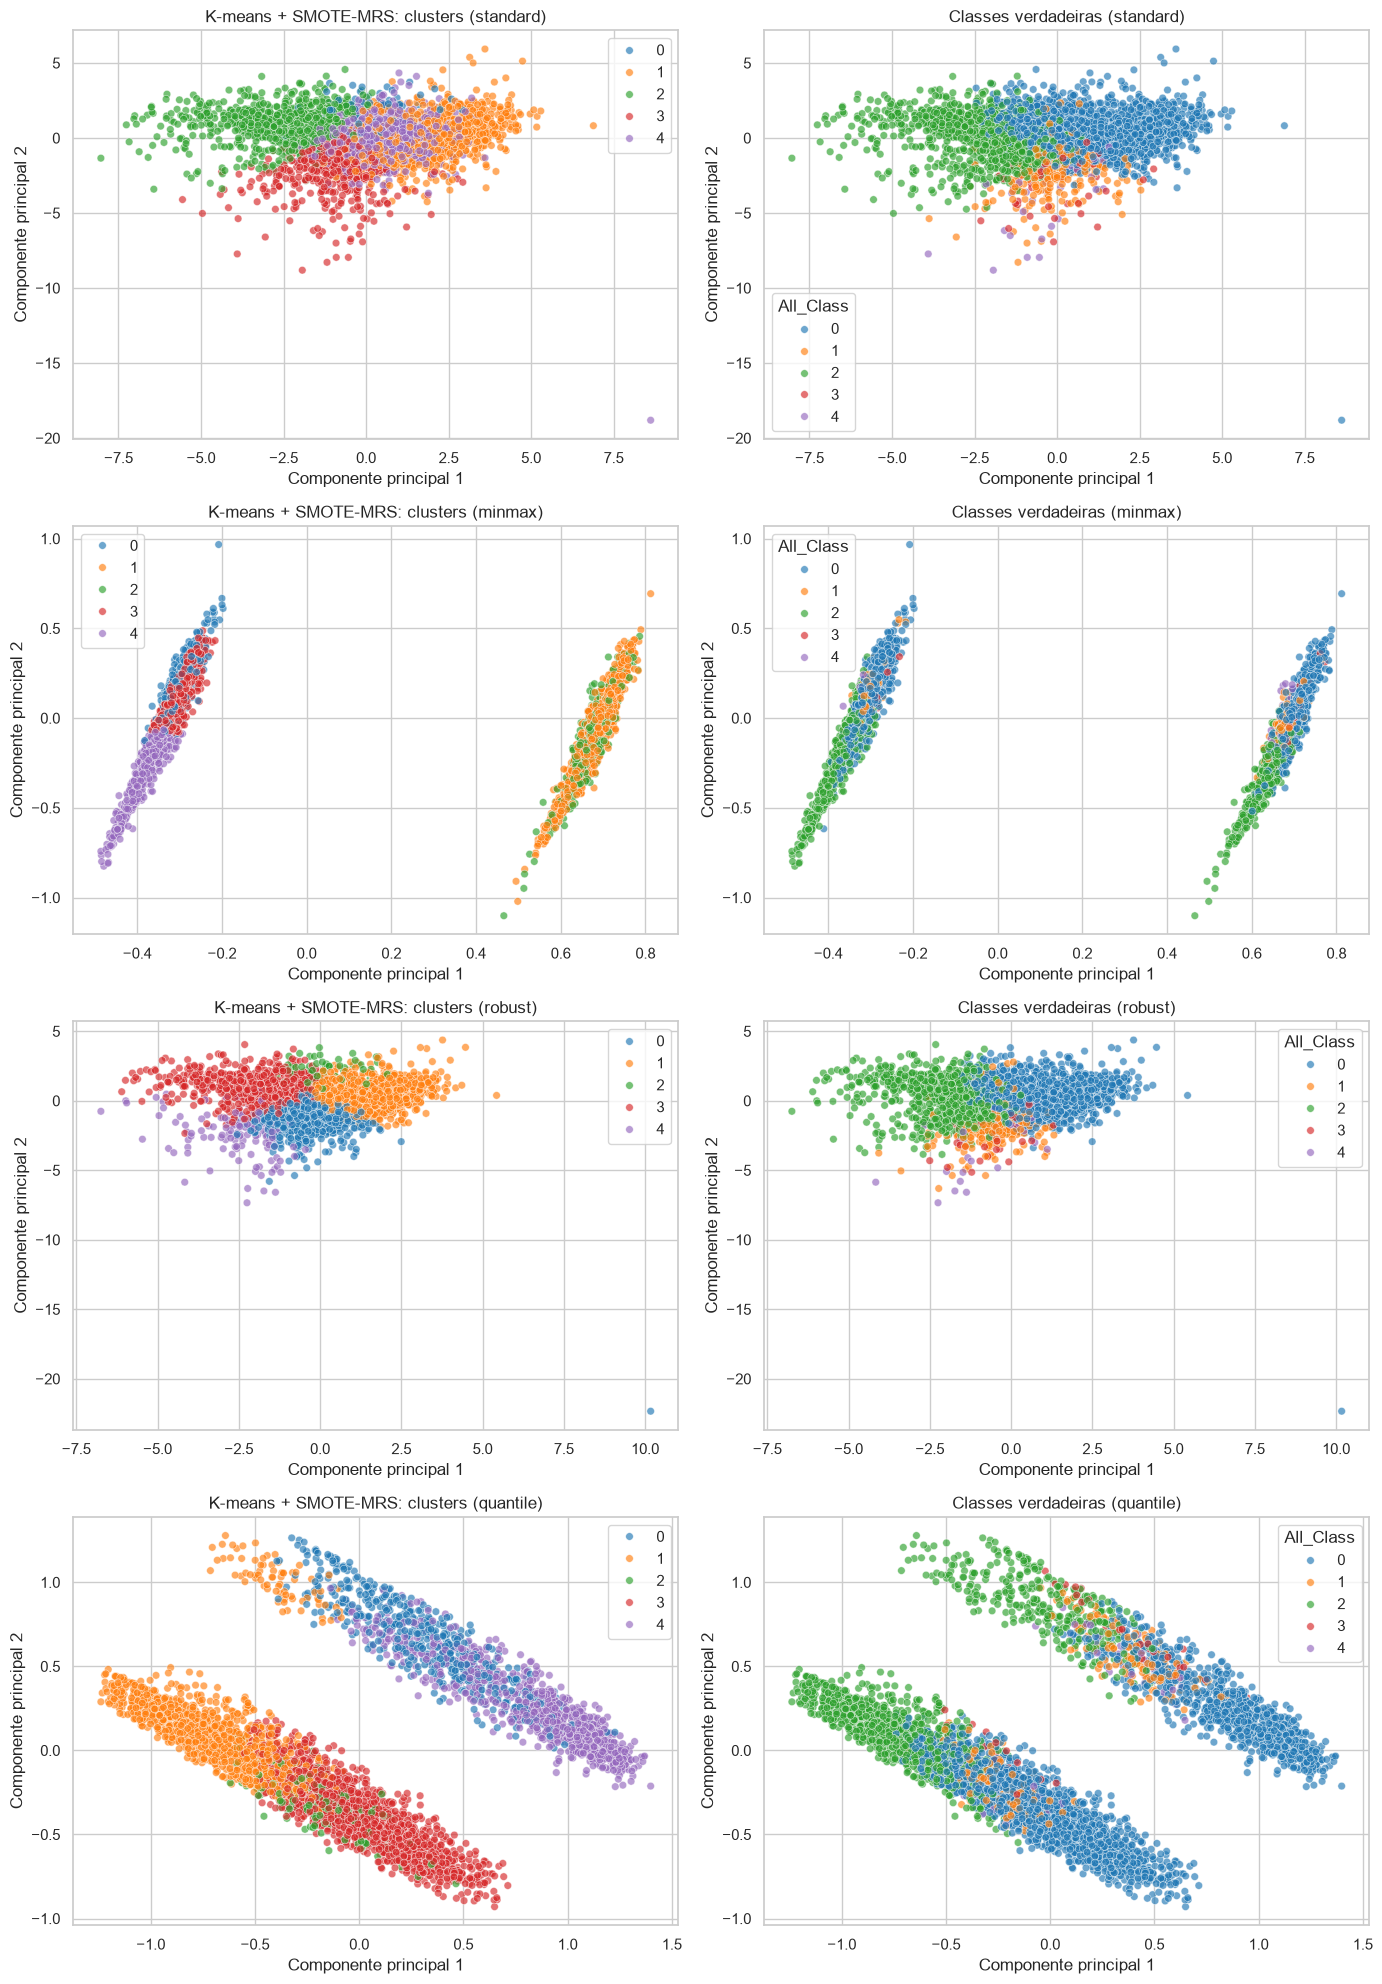

In [158]:
n_scalers = len(scalers)
fig, axes = plt.subplots(n_scalers, 2, figsize=(14, 5 * n_scalers))

if n_scalers == 1:
    axes = np.expand_dims(axes, axis=0)

for row, (nome_scaler, pipeline) in enumerate(scalers.items()):
    X_test_transformado = pipeline[:-1].transform(X_test)
    clusters_test = results[nome_scaler]

    pca = PCA(n_components=2, random_state=42)
    X_test_pca = pca.fit_transform(X_test_transformado)

    sns.scatterplot(
        x=X_test_pca[:, 0],
        y=X_test_pca[:, 1],
        hue=clusters_test,
        palette="tab10",
        s=30,
        alpha=0.65,
        ax=axes[row, 0],
    )
    axes[row, 0].set_title(f"K-means + SMOTE-MRS: clusters ({nome_scaler})")
    axes[row, 0].set_xlabel("Componente principal 1")
    axes[row, 0].set_ylabel("Componente principal 2")

    sns.scatterplot(
        x=X_test_pca[:, 0],
        y=X_test_pca[:, 1],
        hue=y_test.squeeze(),
        palette="tab10",
        s=30,
        alpha=0.65,
        ax=axes[row, 1],
    )
    axes[row, 1].set_title(f"Classes verdadeiras ({nome_scaler})")
    axes[row, 1].set_xlabel("Componente principal 1")
    axes[row, 1].set_ylabel("Componente principal 2")

plt.tight_layout()
plt.show()

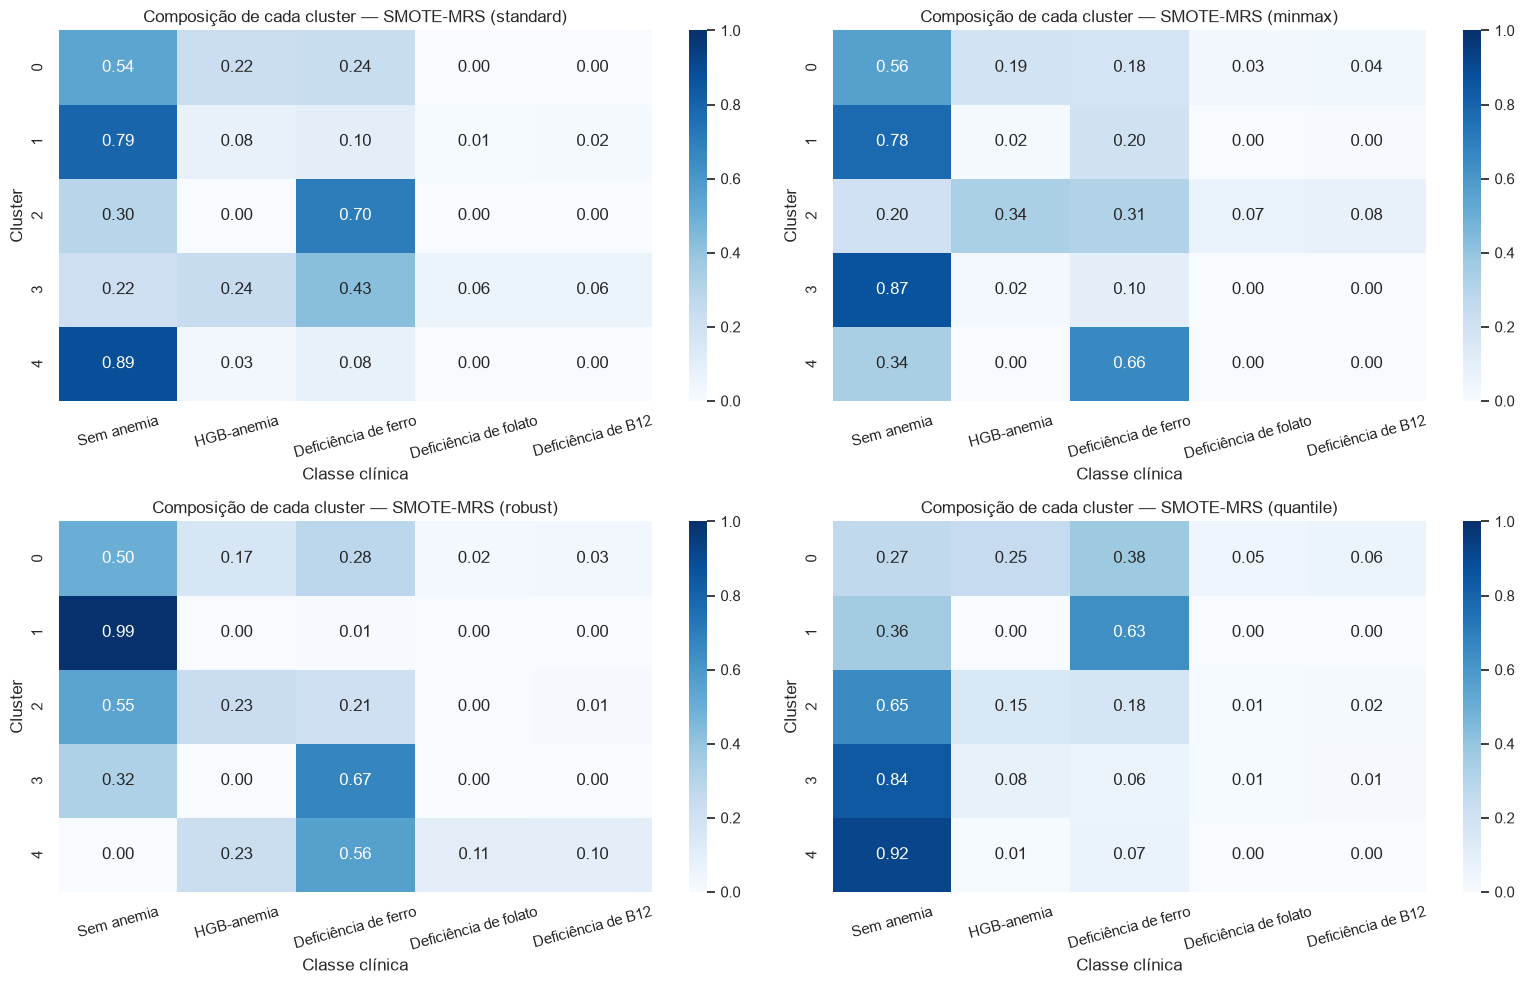

In [163]:
def heatmap_clusters(normalize, titulo):
    n_scalers = len(results)
    ncols = 2
    nrows = math.ceil(n_scalers / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 5 * nrows))
    axes_flat = np.atleast_1d(axes).ravel()

    for ax, (nome_scaler, clusters_test) in zip(axes_flat, results.items()):
        tabela = pd.crosstab(
            pd.Series(clusters_test, name="Cluster"),
            pd.Series(y_test.squeeze(), name="Classe real"),
            normalize=normalize,
        )
        tabela.columns = [NOMES_CLASSES.get(c, str(c)) for c in tabela.columns]

        sns.heatmap(tabela, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
        ax.set_title(f"{titulo} — SMOTE-MRS ({nome_scaler})")
        ax.set_xlabel("Classe clínica")
        ax.set_ylabel("Cluster")
        ax.tick_params(axis="x", rotation=15)

    for ax in axes_flat[n_scalers:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


heatmap_clusters("index", "Composição de cada cluster")

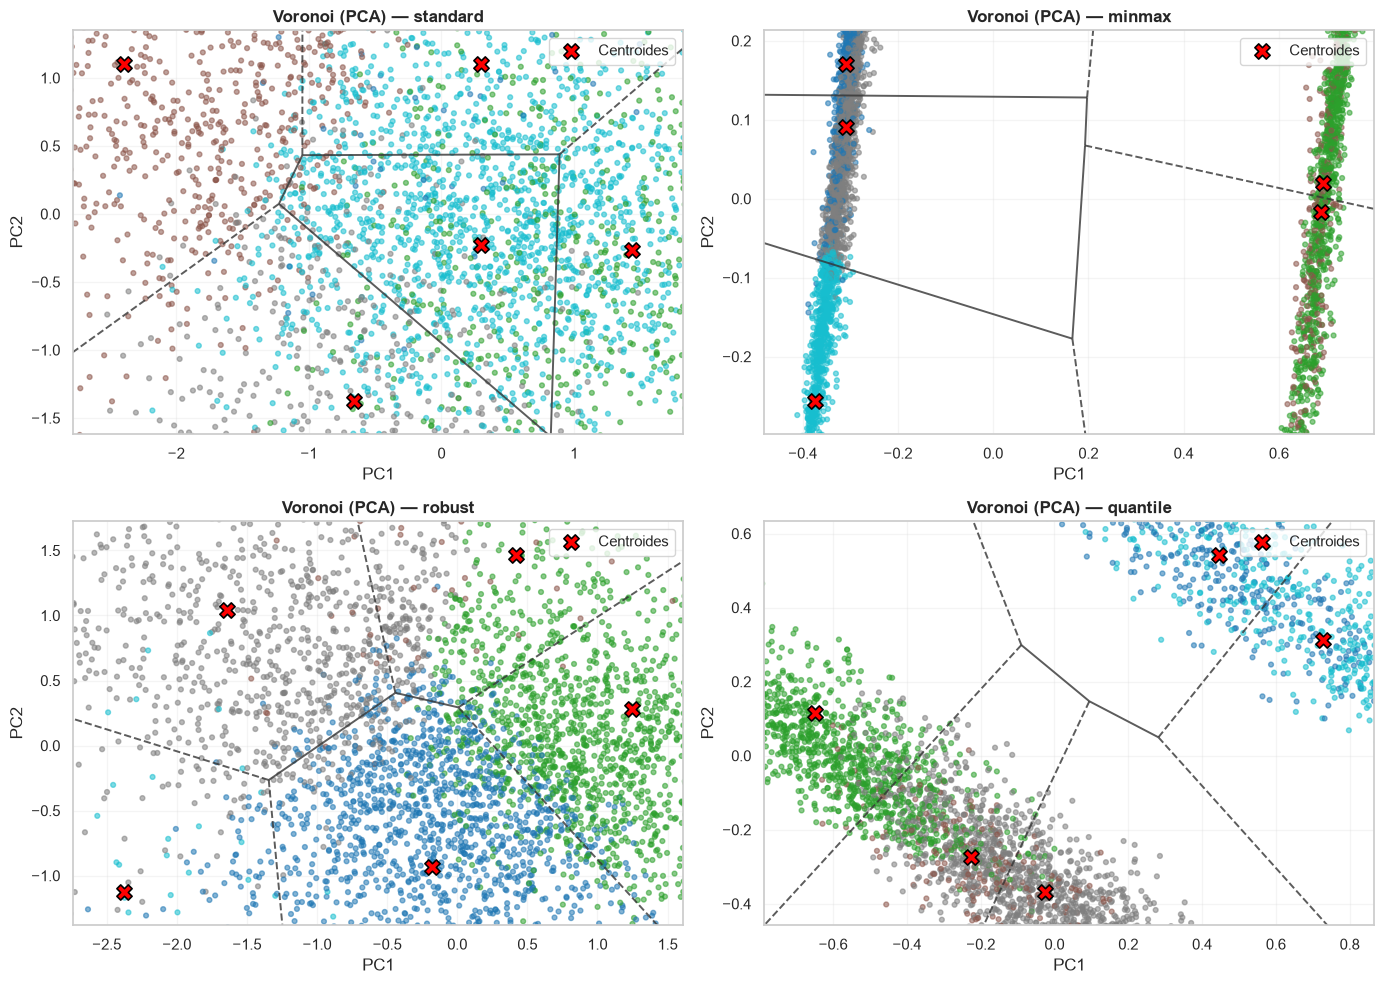

In [160]:
scalers_mrs = {nome: clone(p.named_steps["scaler"]) for nome, p in scalers.items()}

smote_scenarios = fit_smote_mrs_scenarios(
    X_train, X_test, y_train.squeeze(),
    n_clusters=N_CLUSTERS, n_groups=R, target_ratio=RATIO,
    random_state=RANDOM_STATE, scalers=scalers_mrs,
)

km_utils.plot_voronoi_grid(smote_scenarios, RANDOM_STATE, figsize=(14, 10))
plt.show()

In [162]:
N_SEMENTES = 10
linhas = []

for name, pipeline in scalers.items():
    scaler = pipeline.named_steps["scaler"]
    Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

    for semente in range(N_SEMENTES):
        base = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=semente).fit(Xs_train)

        X_mrs, _, _ = smote_mrs(
            Xs_train, y_tr, n_groups=R, target_ratio=RATIO, random_state=semente
        )
        mrs = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=semente).fit(X_mrs)

        for cenario, modelo in [("Sem SMOTE", base), ("SMOTE-MRS", mrs)]:
            clusters = modelo.predict(Xs_test)
            linhas.append({
                "Cenário": cenario,
                "Scaler": name,
                "Semente": semente,
                "ARI": adjusted_rand_score(y_test.squeeze(), clusters),
                "NMI": normalized_mutual_info_score(y_test.squeeze(), clusters),
                "Silhouette": silhouette_score(Xs_test, clusters),
                "Davies-Bouldin": davies_bouldin_score(Xs_test, clusters),
                "Calinski-Harabasz": calinski_harabasz_score(Xs_test, clusters),
            })

repeticoes = pd.DataFrame(linhas)

resumo_sementes = repeticoes.groupby(["Scaler", "Cenário"])[
    ["ARI", "NMI", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]
].agg("mean").reset_index()

cols_para_formatar = [c for c in resumo_sementes.columns if c not in ["Scaler", "Cenário"]]
display(resumo_sementes.style.format(formatter="{:.4f}", subset=cols_para_formatar))

,Scaler,Cenário,ARI,NMI,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,minmax,SMOTE-MRS,0.1546,0.1784,0.1995,1.7769,3295.6841
1,minmax,Sem SMOTE,0.1981,0.2117,0.2524,1.5497,3611.5404
2,quantile,SMOTE-MRS,0.1709,0.2022,0.1656,1.8656,992.4738
3,quantile,Sem SMOTE,0.1815,0.2714,0.2116,1.6275,1198.0636
4,robust,SMOTE-MRS,0.2657,0.2812,0.1547,1.6622,642.6950
5,robust,Sem SMOTE,0.1771,0.2794,0.1373,1.7586,824.3442
6,standard,SMOTE-MRS,0.2238,0.2138,0.1673,1.6865,686.9703
7,standard,Sem SMOTE,0.1971,0.2947,0.1555,1.6830,855.3396
